In [1]:
from sklearn.datasets import load_iris
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
iris=load_iris()
X=iris.data
y=iris.target

In [3]:
# scale
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)


<Axes: >

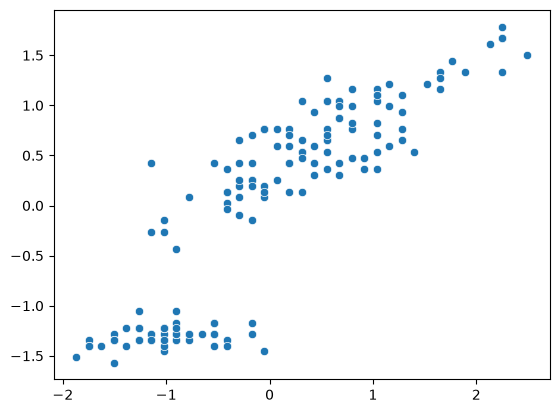

In [4]:
# visualise
sns.scatterplot(x=X_scaled[:,0],y=X_scaled[:,2])

In [6]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan.fit(X_scaled)

# 4. Extract cluster assignments
# Outliers/Noise are automatically assigned a label of -1
labels = dbscan.labels_

<Axes: >

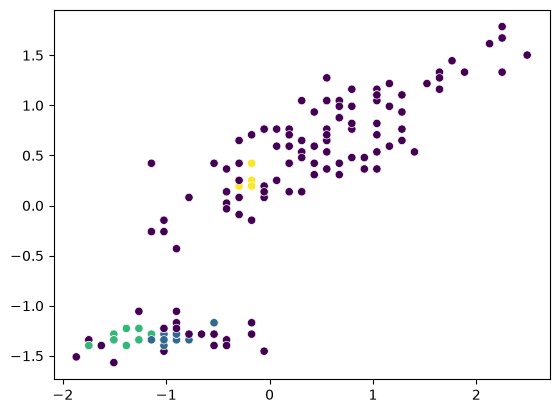

In [7]:
# visualise
sns.scatterplot(x=X_scaled[:,0],y=X_scaled[:,2],c=labels)

In [8]:
labels

array([ 0,  1,  1,  1,  0, -1, -1,  0, -1,  1, -1,  0,  1, -1, -1, -1, -1,
        0, -1, -1,  0, -1, -1, -1, -1,  1,  0,  0,  0,  1,  1, -1, -1, -1,
        1, -1, -1,  0, -1,  0,  0, -1,  1, -1, -1,  1, -1,  1, -1,  0, -1,
       -1, -1, -1, -1,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1,  2, -1, -1, -1, -1, -1, -1,  2,  2, -1, -1,  2, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])

In [9]:
# Non linear data


In [10]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

# 1. Generate or load your dataset (e.g., a non-linear moon-shaped dataset)
X, y = make_moons(n_samples=500, noise=0.1, random_state=42)

# 2. Crucial Step: Scale your data (DBSCAN is highly sensitive to distance scales)
X_scaled = StandardScaler().fit_transform(X)

# 3. Instantiate and fit the DBSCAN model
# eps: max distance between two points to be considered neighbors
# min_samples: minimum number of points required to form a dense region
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan.fit(X_scaled)

# 4. Extract cluster assignments
# Outliers/Noise are automatically assigned a label of -1
labels = dbscan.labels_

# 5. Evaluate the results
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"Estimated number of clusters: {n_clusters}")
print(f"Estimated number of noise points: {n_noise}")

Estimated number of clusters: 2
Estimated number of noise points: 1


<Axes: >

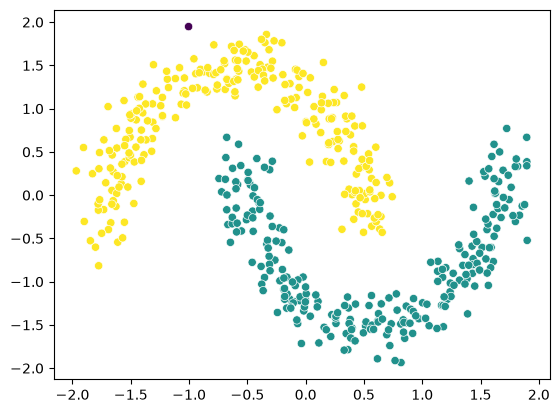

In [12]:
# visualise
sns.scatterplot(x=X_scaled[:,0],y=X_scaled[:,1],c=labels)